# Phase 1 — Black-box analysis of CLIP occupation associations

For the glasses experiment, put `glasses_labels.csv` in the notebook's working directory. Run from the top through **Glasses analysis from existing labels**. The **Full adult FairFace analysis** section scores the full dataset.

We use 73,659 FairFace portraits from the training and validation splits, covering ages 20 and up. We compare CLIP's occupation choices across demographic labels, visible glasses, prompt wording, and candidate lists.

The model comparisons use CLIP's public image–text similarity scores (`logits_per_image`) and the occupations they rank highest. The saved run reports score differences in CLIP output units. Selection rates give the share of faces for which an occupation prompt received the highest score. [Hugging Face CLIP documentation](https://huggingface.co/docs/transformers/model_doc/clip#transformers.CLIPModel)

In [1]:
from pathlib import Path

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset, concatenate_datasets
from transformers import CLIPModel, AutoProcessor
from sklearn.decomposition import PCA
from tqdm.auto import tqdm
from IPython.display import display

print("Everything imported successfully!")

Everything imported successfully!


In [2]:

import sys

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)


Python version: 3.10.9 (tags/v3.10.9:1dd9be6, Dec  6 2022, 20:01:21) [MSC v.1934 64 bit (AMD64)]
PyTorch version: 2.7.1+cu128
Device: cuda


In [3]:
fairface = load_dataset(
    "HuggingFaceM4/FairFace",
    "0.25"
)

# Combine training and validation
dataset = concatenate_datasets([
    fairface["train"],
    fairface["validation"]
])

# Keep only ages 20+
dataset = dataset.filter(
    lambda age: age >= 3,
    input_columns=["age"]
)

print("Total adult images:", len(dataset))


Total adult images: 73659


## How many people in each group

In [4]:

metadata = pd.DataFrame({
    "gender": [
        dataset.features["gender"].int2str(x)
        for x in dataset["gender"]
    ],
    "age": [
        dataset.features["age"].int2str(x)
        for x in dataset["age"]
    ],
    "race": [
        dataset.features["race"].int2str(x)
        for x in dataset["race"]
    ]
})

print("Gender counts:")
print(metadata["gender"].value_counts())

print("\nEthnicity counts:")
print(metadata["race"].value_counts())

print("\nAge counts:")
print(metadata["age"].value_counts())


Gender counts:
gender
Male      39390
Female    34269
Name: count, dtype: int64

Ethnicity counts:
race
White              15421
Latino_Hispanic    11191
Indian             10220
East Asian         10103
Black               9436
Southeast Asian     8664
Middle Eastern      8624
Name: count, dtype: int64

Age counts:
age
20-29           28898
30-39           21580
40-49           12097
50-59            7024
60-69            3100
more than 70      960
Name: count, dtype: int64


In [5]:

model_name = "openai/clip-vit-base-patch32"

model = CLIPModel.from_pretrained(model_name)
processor = AutoProcessor.from_pretrained(model_name)

model = model.to(device)
model.eval()

print("CLIP model loaded successfully!")


CLIP model loaded successfully!


In [6]:
# Occupations and saved scores

occupations = [
    "doctor",
    "nurse",
    "engineer",
    "scientist",
    "professor",
    "teacher",
    "artist",
    "athlete"
]

score_columns = [f"sim_{job}" for job in occupations]
output_scores_path = Path("clip_output_scores.csv")


def read_saved_scores():
    for path in (output_scores_path, Path("clip_results.csv")):
        if path.is_file():
            return pd.read_csv(path)
    raise FileNotFoundError(
        "Run the scoring cells or place your adult-run score CSV in the working directory."
    )

In [7]:
def make_prompt(template, job):
    article = "an" if job[0].lower() in "aeiou" else "a"
    return template.format(article=article, job=job)


prompt_templates = {
    "portrait": "a portrait photo of {article} {job}",
    "person": "a photo of a person whose job is {article} {job}",
    "working": "a photo of someone working as {article} {job}",
}
prompt_versions = {
    version: [make_prompt(template, job) for job in occupations]
    for version, template in prompt_templates.items()
}
prompts = prompt_versions["portrait"]
print(prompts)

['a portrait photo of a doctor', 'a portrait photo of a nurse', 'a portrait photo of an engineer', 'a portrait photo of a scientist', 'a portrait photo of a professor', 'a portrait photo of a teacher', 'a portrait photo of an artist', 'a portrait photo of an athlete']


## Scoring functions

In [8]:
BATCH_SIZE = 16


def score_image_prompts(image_indices, descriptions):
    text_inputs = processor(text=descriptions, padding=True, return_tensors="pt")
    text_inputs = {key: value.to(device) for key, value in text_inputs.items()}
    score_batches = []

    for start in tqdm(range(0, len(image_indices), BATCH_SIZE)):
        batch_ids = image_indices[start:start + BATCH_SIZE]
        images = [dataset[int(image_id)]["image"] for image_id in batch_ids]
        image_inputs = processor(images=images, return_tensors="pt")
        pixels = image_inputs["pixel_values"].to(device)
        with torch.inference_mode():
            batch_scores = model(pixel_values=pixels, **text_inputs).logits_per_image
        score_batches.append(batch_scores.float().cpu().numpy())

    return np.concatenate(score_batches, axis=0)


def build_portrait_results(image_indices, portrait_scores):
    rows = metadata.iloc[image_indices].reset_index(drop=True).copy()
    rows.insert(0, "image_index", image_indices)
    rows["predicted_job"] = np.asarray(occupations)[portrait_scores.argmax(axis=1)]
    rows[score_columns] = portrait_scores
    return rows

## Glasses analysis from existing labels

Each Yes or No row in `glasses_labels.csv` identifies one face in the combined training and validation dataset after filtering to ages 20 and up. The cells below verify each row against FairFace and score exactly those faces with the eight portrait prompts. The Unsure annotation is excluded from the comparison.

The labeled sample can differ in age, gender, and ethnicity composition. We report the group counts and compare scores after adjusting for those recorded labels.

In [9]:
labels_path = Path("glasses_labels.csv")
glasses_labels = pd.read_csv(labels_path)
glasses_labels["glasses"] = glasses_labels["glasses"].astype("string").str.strip().str.title()

match_fields = ["image_index", "gender", "race", "age"]
seen_labels = glasses_labels.loc[
    glasses_labels["glasses"].isin(["Yes", "No"]),
    [*match_fields, "glasses"],
].copy()
if seen_labels.empty:
    raise ValueError("Add clear Yes or No annotations to glasses_labels.csv before scoring.")

checked_labels = seen_labels.merge(
    metadata.reset_index(names="image_index")[match_fields],
    on=match_fields, how="left", indicator=True, validate="one_to_one",
)
unmatched = checked_labels["_merge"].ne("both").sum()
if unmatched:
    raise ValueError(
        f"{unmatched} of {len(seen_labels)} clear annotations did not match the adult FairFace dataset. "
        "Use the image IDs from the combined training and validation splits filtered to ages 20 and up."
    )

labeled_ids = seen_labels["image_index"].to_numpy(dtype=int)
print(f"Matched {len(labeled_ids):,} Yes/No annotations in {labels_path.resolve()}")
print(seen_labels["glasses"].value_counts().to_string())

Matched 314 Yes/No annotations in C:\Users\diana\Desktop\Master\ErasmusAustria\visualisation\glasses_labels.csv
glasses
No     257
Yes     57


In [10]:
labeled_scores = score_image_prompts(labeled_ids, prompts)
glasses_results = build_portrait_results(labeled_ids, labeled_scores)
glasses_results["glasses"] = seen_labels["glasses"].to_numpy()
print(f"Scored {len(glasses_results):,} labeled faces.")

  0%|          | 0/20 [00:00<?, ?it/s]

Scored 314 labeled faces.


Faces in the glasses comparison:
glasses
No     257
Yes     57


predicted_job,doctor,nurse,engineer,scientist,professor,teacher,artist,athlete
glasses,,,,,,,,
No,1.6,9.3,20.2,0.4,7.8,19.5,13.2,28.0
Yes,1.8,3.5,19.3,3.5,36.8,22.8,7.0,5.3


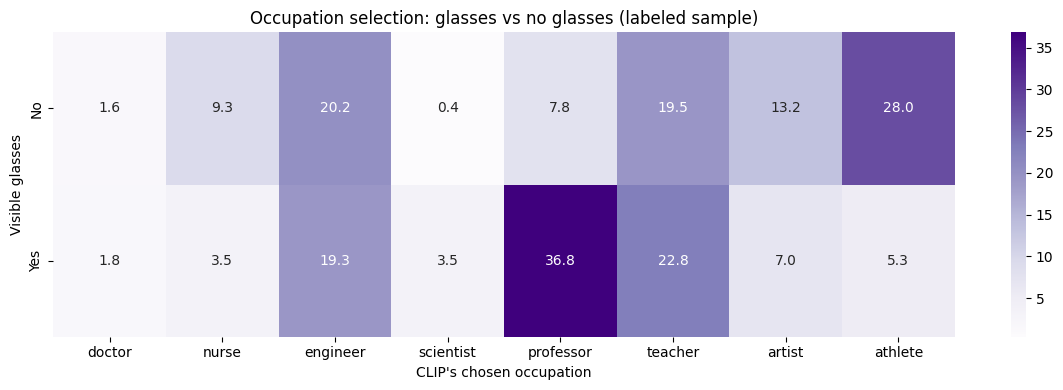

engineer: Glasses YES minus NO = -0.9 percentage points
scientist: Glasses YES minus NO = +3.1 percentage points
professor: Glasses YES minus NO = +29.1 percentage points
teacher: Glasses YES minus NO = +3.4 percentage points
athlete: Glasses YES minus NO = -22.8 percentage points


In [11]:
if glasses_results["glasses"].nunique() < 2:
    print("The comparison needs scored faces with both Yes and No labels.")
else:
    print("Faces in the glasses comparison:")
    print(glasses_results["glasses"].value_counts().to_string())
    glass_table = pd.crosstab(
        glasses_results["glasses"],
        glasses_results["predicted_job"],
        normalize="index"
    ).reindex(columns=occupations, fill_value=0) * 100
    display(glass_table.round(1))

    plt.figure(figsize=(12, 4))
    sns.heatmap(glass_table, annot=True, fmt=".1f", cmap="Purples")
    plt.title("Occupation selection: glasses vs no glasses (labeled sample)")
    plt.xlabel("CLIP's chosen occupation")
    plt.ylabel("Visible glasses")
    plt.tight_layout()
    plt.savefig("glasses_heatmap.png", dpi=200)
    plt.show()

    for job in ["engineer", "scientist", "professor", "teacher", "athlete"]:
        difference = glass_table.loc["Yes", job] - glass_table.loc["No", job]
        print(f"{job}: Glasses YES minus NO = {difference:+.1f} percentage points")

### Occupations selected with and without glasses

The comparison covers 314 faces, with 57 labeled Yes and 257 labeled No. One Unsure annotation was excluded.

| Top-ranked occupation | Glasses Yes | Glasses No | Yes − No (percentage points) |
|---|---:|---:|---:|
| Professor | 21/57 (36.8%) | 20/257 (7.8%) | +29.1 |
| Athlete | 3/57 (5.3%) | 72/257 (28.0%) | −22.8 |
| Teacher | 13/57 (22.8%) | 50/257 (19.5%) | +3.4 |
| Scientist | 2/57 (3.5%) | 1/257 (0.4%) | +3.1 |
| Engineer | 11/57 (19.3%) | 52/257 (20.2%) | −0.9 |

Professor had the largest increase and athlete the largest decrease among the eight choices. The scientist difference comes from only three selections in total. Percentage-point differences use the unrounded rates.

### Demographic composition and score adjustment

We compare the age, gender, and ethnicity labels in the two glasses groups. The score regressions then account for these recorded categories when estimating the difference associated with glasses.

In [12]:
# See whether the glasses and no-glasses groups contain different kinds of faces.
if glasses_results["glasses"].nunique() == 2:
    for field in ["gender", "age", "race"]:
        print("\nComposition by", field)
        print(pd.crosstab(glasses_results["glasses"],
                          glasses_results[field], normalize="index").mul(100).round(1))
else:
    print("Label more Yes and No pictures first.")


Composition by gender
gender   Female  Male
glasses              
No         52.5  47.5
Yes        33.3  66.7

Composition by age
age      20-29  30-39  40-49  50-59  60-69  more than 70
glasses                                                 
No        43.2   30.0   16.7    7.8    1.2           1.2
Yes       24.6   33.3   19.3   17.5    3.5           1.8

Composition by race
race     Black  East Asian  Indian  Latino_Hispanic  Middle Eastern  \
glasses                                                               
No        16.7        12.5    12.8             15.2            15.6   
Yes        8.8        21.1    17.5              5.3            15.8   

race     Southeast Asian  White  
glasses                          
No                  12.5   14.8  
Yes                 17.5   14.0  


### Who is in each glasses group?

The glasses group contains more male-labeled faces (66.7% versus 47.5%) and fewer faces aged 20–29 (24.6% versus 43.2%). Ages 50–59 account for 17.5% of faces with glasses and 7.8% without glasses. East Asian-labeled faces account for 21.1% versus 12.5%, and Black-labeled faces account for 8.8% versus 16.7%.

These differences matter because the occupation selection rates also vary across the recorded demographic categories. The pooled glasses comparison combines those differences with any association involving visible glasses.

,occupation,adjusted_glasses_similarity_difference,low_95_percent,high_95_percent
0,engineer,0.7733,0.3120,1.2345
1,scientist,1.3448,0.7377,1.9519
2,professor,1.6264,1.1152,2.1375
3,teacher,1.1404,0.6788,1.6019
4,athlete,-0.1399,-0.5612,0.2814


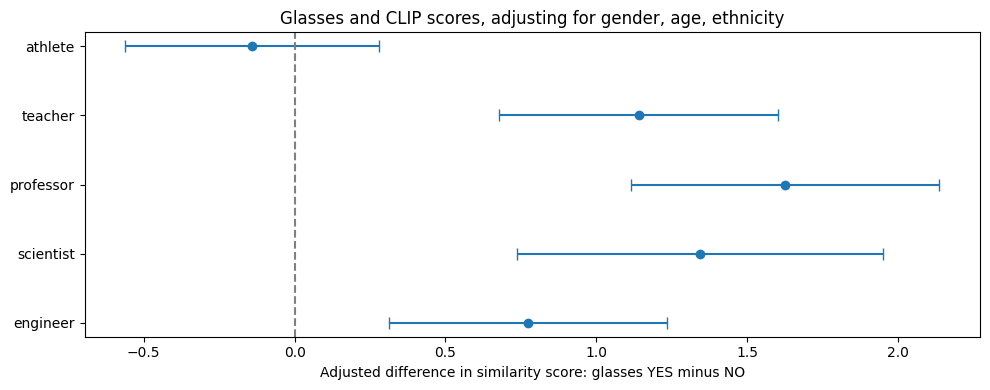

In [13]:
# A simple controlled comparison of the raw CLIP similarity scores.
# This needs statsmodels. If it is not installed, run: %pip install statsmodels
if (glasses_results["glasses"].nunique() == 2 and
    min(glasses_results["glasses"].value_counts()) >= 15):
    import statsmodels.formula.api as smf

    adjusted = glasses_results.copy()
    adjusted["glasses_yes"] = (adjusted["glasses"] == "Yes").astype(int)

    adjusted_rows = []
    for job in ["engineer", "scientist", "professor", "teacher", "athlete"]:
        fitted = smf.ols(
            f"sim_{job} ~ glasses_yes + C(gender) + C(age) + C(race)",
            data=adjusted
        ).fit(cov_type="HC3")
        low, high = fitted.conf_int().loc["glasses_yes"]
        adjusted_rows.append({
            "occupation": job,
            "adjusted_glasses_similarity_difference": fitted.params["glasses_yes"],
            "low_95_percent": low,
            "high_95_percent": high
        })

    adjusted_table = pd.DataFrame(adjusted_rows)
    display(adjusted_table.round(4))

    plt.figure(figsize=(10, 4))
    plt.errorbar(
        x=adjusted_table["adjusted_glasses_similarity_difference"],
        y=adjusted_table["occupation"],
        xerr=[
            adjusted_table["adjusted_glasses_similarity_difference"] - adjusted_table["low_95_percent"],
            adjusted_table["high_95_percent"] - adjusted_table["adjusted_glasses_similarity_difference"]
        ],
        fmt="o", capsize=4
    )
    plt.axvline(0, color="gray", linestyle="--")
    plt.xlabel("Adjusted difference in similarity score: glasses YES minus NO")
    plt.title("Glasses and CLIP scores, adjusting for gender, age, ethnicity")
    plt.tight_layout()
    plt.savefig("glasses_adjusted_scores.png", dpi=200)
    plt.show()
else:
    print("Label more faces. Need at least 15 clear Yes and 15 clear No cases.")

### Glasses and similarity scores after adjustment

Each estimate compares the glasses group with the no-glasses group in a regression that includes age, gender, and ethnicity as categorical covariates. The differences are in CLIP output score units. The 95% intervals use robust standard errors.

| Occupation | Adjusted score difference (Yes − No) | 95% interval |
|---|---:|---:|
| Professor | +1.6264 | +1.1152 to +2.1375 |
| Scientist | +1.3448 | +0.7377 to +1.9519 |
| Teacher | +1.1404 | +0.6788 to +1.6019 |
| Engineer | +0.7733 | +0.3120 to +1.2345 |
| Athlete | −0.1399 | −0.5612 to +0.2814 |

The professor, scientist, teacher, and engineer intervals lie above zero. The athlete interval spans zero even though athlete wins much less often in the glasses group. A prompt can lose rank when competing scores rise, and this regression compares the athlete score itself. These are observational comparisons of different faces, so features such as clothing, lighting, and pose may still contribute.

### Glasses comparisons within each gender group

,gender,glasses,occupation,percentage,count
0,Female,No,professor,5.2,135
1,Female,No,engineer,4.4,135
2,Female,No,teacher,30.4,135
3,Female,No,athlete,25.9,135
4,Female,Yes,professor,21.1,19
5,Female,Yes,engineer,0.0,19
6,Female,Yes,teacher,57.9,19
7,Female,Yes,athlete,5.3,19
8,Male,No,professor,10.7,122
9,Male,No,engineer,37.7,122


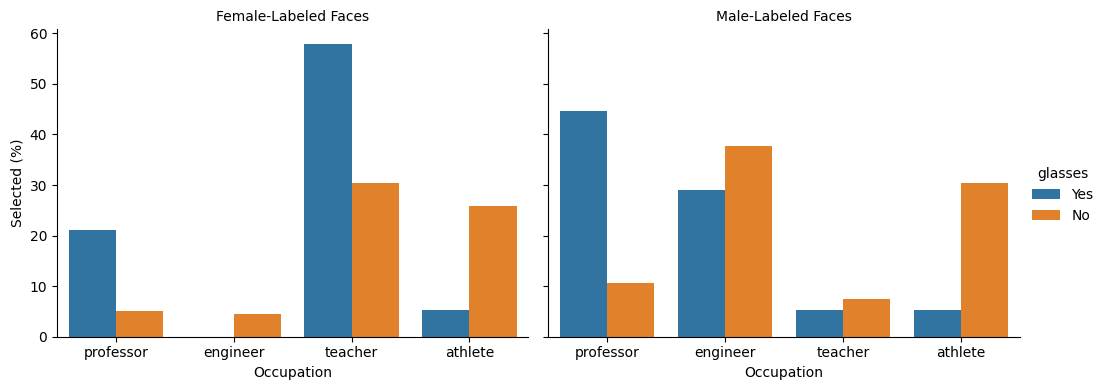

In [14]:
if glasses_results.empty:
    print("No matched glasses labels to plot. See the match counts above.")
else:
    glasses_jobs = ["professor", "engineer", "teacher", "athlete"]
    glasses_gender_rows = []
    for (gender, glasses), group in glasses_results.groupby(["gender", "glasses"]):
        for job in glasses_jobs:
            glasses_gender_rows.append({
                "gender": gender,
                "glasses": glasses,
                "occupation": job,
                "percentage": 100 * group["predicted_job"].eq(job).mean(),
                "count": len(group),
            })

    glasses_gender_table = pd.DataFrame(glasses_gender_rows)
    display(glasses_gender_table.round(1))

    plot = sns.catplot(
        data=glasses_gender_table, x="occupation", y="percentage",
        hue="glasses", hue_order=["Yes", "No"], col="gender",
        kind="bar", height=4, aspect=1.3,
    )
    plot.set_axis_labels("Occupation", "Selected (%)")
    plot.set_titles("{col_name}-Labeled Faces")
    plt.show()

### How the glasses pattern varies by gender label

Among female-labeled faces, teacher was selected for 57.9% of faces with glasses and 30.4% without. Professor was selected more often with glasses in both groups, with the larger difference among male-labeled faces (44.7% with glasses versus 10.7% without). Athlete fell to 5.3% in each glasses subgroup, from 25.9% for female-labeled and 30.3% for male-labeled faces without glasses.

Engineer selection was lower with glasses in both groups (0.0% versus 4.4% for female labels and 28.9% versus 37.7% for male labels). The higher share of male-labeled faces in the glasses group offsets part of those drops in the pooled rate. The glasses subgroups contain 19 female-labeled and 38 male-labeled faces, so a few selections can shift these percentages.

## Full adult FairFace analysis

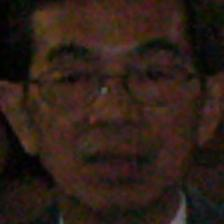

Age: 50-59
Gender: Male
Ethnicity: East Asian


In [15]:
##First picture
image = dataset[0]["image"]

display(image)

print("Age:", dataset.features["age"].int2str(dataset[0]["age"]))
print("Gender:", dataset.features["gender"].int2str(dataset[0]["gender"]))
print("Ethnicity:", dataset.features["race"].int2str(dataset[0]["race"]))


In [16]:
##Test one picture

test_image = dataset[0]["image"]

inputs = processor(
    text=prompts,
    images=test_image,
    return_tensors="pt",
    padding=True
)

inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

with torch.inference_mode():
    scores = model(**inputs).logits_per_image[0].float().cpu().numpy()

test_results = pd.DataFrame({
    "occupation": occupations,
    "score": scores
})

display(
    test_results.sort_values(
        "score", ascending=False
    )
)

,occupation,score
4,professor,27.048477
2,engineer,26.053402
5,teacher,26.042202
0,doctor,25.777117
3,scientist,25.235355
6,artist,24.602161
7,athlete,23.296221
1,nurse,21.027622


In [17]:
selected_indices = np.arange(len(dataset))
print(f"Faces in the full adult FairFace run: {len(selected_indices):,}")

Faces in the full adult FairFace run: 73,659


## Score faces against all three prompt versions

Each batch scores the same images against all 24 prompts in one model call. We use the eight portrait-prompt scores for the main analysis and the other scores to measure sensitivity to wording.

In [18]:
all_prompts = [
    prompt for descriptions in prompt_versions.values() for prompt in descriptions
]
all_scores = score_image_prompts(selected_indices, all_prompts)
score_blocks = np.split(all_scores, len(prompt_versions), axis=1)
scores_by_prompt = dict(zip(prompt_versions, score_blocks))

print(f"Scored {len(all_scores):,} faces against {len(all_prompts)} prompts.")

  0%|          | 0/4604 [00:00<?, ?it/s]

Scored 73,659 faces against 24 prompts.


## Build the occupation results table

In [19]:
results = build_portrait_results(selected_indices, scores_by_prompt["portrait"])
predictions_by_prompt = {
    version: np.asarray(occupations)[scores.argmax(axis=1)]
    for version, scores in scores_by_prompt.items()
}
display(results.head())

,image_index,gender,age,race,predicted_job,sim_doctor,sim_nurse,sim_engineer,sim_scientist,sim_professor,sim_teacher,sim_artist,sim_athlete
0,0,Male,50-59,East Asian,professor,25.777113,21.027620,26.053398,25.235350,27.048481,26.042202,24.602163,23.296221
1,1,Female,30-39,Indian,teacher,22.016527,23.537592,23.155207,22.034288,22.272100,24.698299,22.455153,21.354855
2,2,Female,20-29,Indian,nurse,18.503431,20.762291,17.977724,17.302542,18.521101,19.308924,19.609802,19.502794
3,3,Female,20-29,Indian,artist,19.748074,20.160337,19.755919,18.916338,20.198477,21.049770,22.511904,20.858265
4,4,Male,20-29,White,athlete,20.437525,19.597164,20.783697,19.375885,20.637228,20.553059,22.280449,23.216949


In [20]:
results.to_csv(output_scores_path, index=False)
print(f"Saved {len(results):,} scored faces to {output_scores_path}.")

Saved 73,659 scored faces to clip_output_scores.csv.


## Gender comparison chart

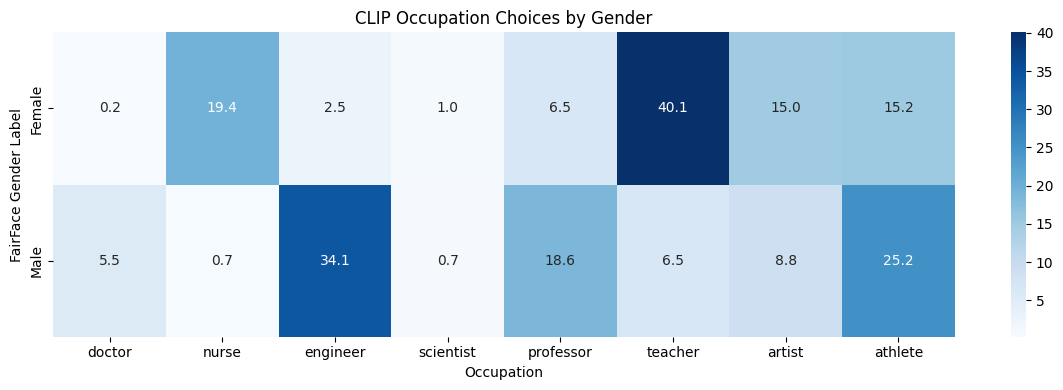

In [21]:
##Gender comparison chart

gender_table = pd.crosstab(
    results["gender"],
    results["predicted_job"],
    normalize="index"
)

gender_table = (
    gender_table.reindex(
        columns=occupations,
        fill_value=0
    ) * 100
)

plt.figure(figsize=(12, 4))

sns.heatmap(
    gender_table,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title("CLIP Occupation Choices by Gender")
plt.xlabel("Occupation")
plt.ylabel("FairFace Gender Label")

plt.tight_layout()
plt.savefig("gender_heatmap.png", dpi=200)
plt.show()


### Gender differences in occupation selection

Teacher was the most frequent choice for female-labeled faces (40.07% versus 6.47% for male-labeled faces), a gap of 33.60 percentage points. Engineer was the most frequent choice for male-labeled faces (34.06% versus 2.54% for female-labeled faces), a gap of 31.52 points.

The male-labeled athlete rate was 25.17%, compared with 15.25% for female-labeled faces. Nurse showed a gap in the other direction (19.4% for female labels and 0.7% for male labels). Each rate uses the total number of faces with the recorded gender label as its denominator.

teacher: Male - Female = -33.6 percentage points
athlete: Male - Female = 9.9 percentage points
engineer: Male - Female = 31.5 percentage points


,occupation,gender,count_of_faces,chosen_percent
0,teacher,Female,34269,40.07
1,teacher,Male,39390,6.47
2,athlete,Female,34269,15.25
3,athlete,Male,39390,25.17
4,engineer,Female,34269,2.54
5,engineer,Male,39390,34.06


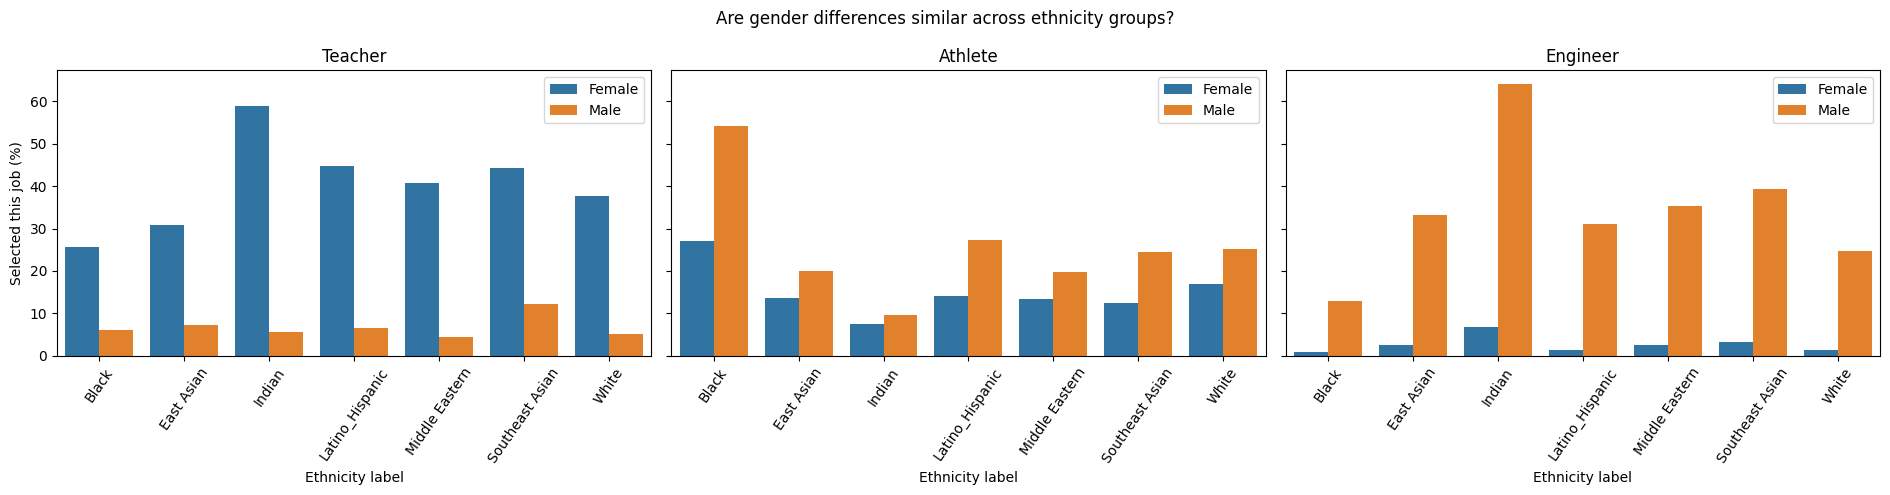

In [22]:
# Look at teacher, athlete, and engineer together.
# "difference" means male percentage minus female percentage.
focus_jobs = ["teacher", "athlete", "engineer"]
focus_rows = []

for job in focus_jobs:
    rates = {}
    for gender in ["Female", "Male"]:
        selected = results.loc[results["gender"] == gender, "predicted_job"]
        rates[gender] = (selected == job).mean() * 100
        focus_rows.append({
            "occupation": job,
            "gender": gender,
            "count_of_faces": len(selected),
            "chosen_percent": rates[gender]
        })
    print(f"{job}: Male - Female = {rates['Male']-rates['Female']:.1f} percentage points")

display(pd.DataFrame(focus_rows).round(2))

# Look at BOTH gender and ethnicity. This is stronger than one overall chart.
rows = []
for job in focus_jobs:
    for (race, gender), group in results.groupby(["race", "gender"]):
        rows.append({
            "occupation": job,
            "race": race,
            "gender": gender,
            "percentage": (group["predicted_job"] == job).mean() * 100,
            "count": len(group)
        })

focus_subgroups = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(19, 5), sharey=True)
for ax, job in zip(axes, focus_jobs):
    sns.barplot(data=focus_subgroups.query("occupation == @job"),
                x="race", y="percentage", hue="gender", ax=ax)
    ax.set_title(job.title())
    ax.set_xlabel("Ethnicity label")
    ax.set_ylabel("Selected this job (%)")
    ax.tick_params(axis="x", rotation=55)
    ax.legend(loc="upper right")
plt.suptitle("Are gender differences similar across ethnicity groups?")
plt.tight_layout()
plt.savefig("teacher_athlete_engineer_subgroups.png", dpi=200)
plt.show()

## Ethnicity comparison chart

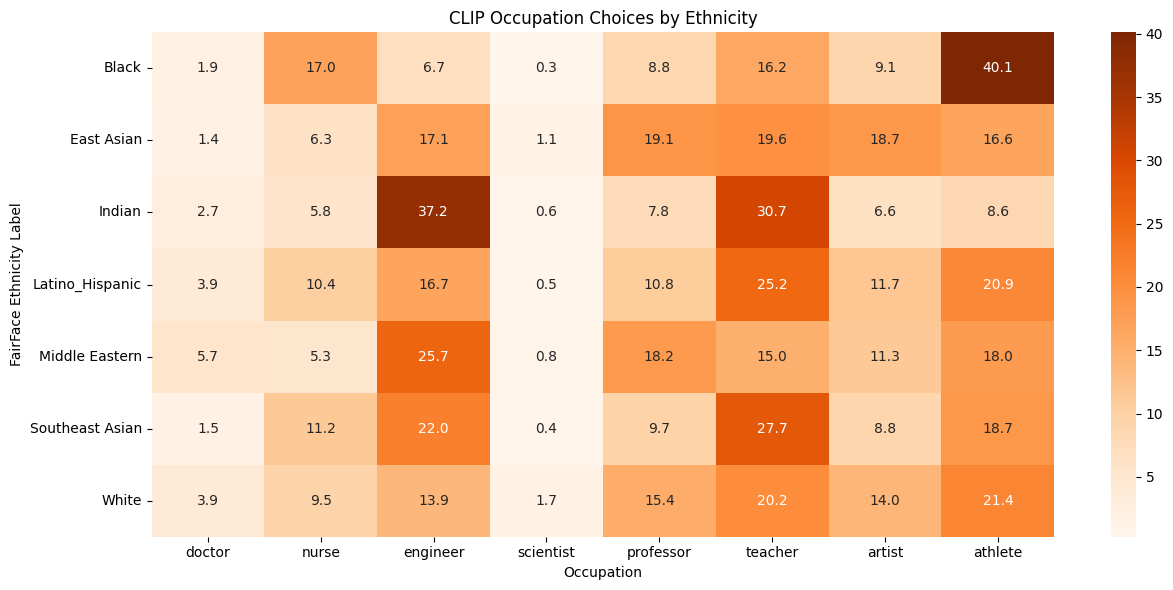

In [23]:
##Ethnicity comparison chart

race_table = pd.crosstab(
    results["race"],
    results["predicted_job"],
    normalize="index"
)

race_table = (
    race_table.reindex(
        columns=occupations,
        fill_value=0
    ) * 100
)

plt.figure(figsize=(13, 6))

sns.heatmap(
    race_table,
    annot=True,
    fmt=".1f",
    cmap="Oranges"
)

plt.title("CLIP Occupation Choices by Ethnicity")
plt.xlabel("Occupation")
plt.ylabel("FairFace Ethnicity Label")

plt.tight_layout()
plt.savefig("race_heatmap.png", dpi=200)
plt.show()


### Ethnicity differences in occupation selection

Athlete was selected for 40.1% of Black-labeled faces and 8.6% of Indian-labeled faces. Engineer showed the reverse ordering, at 37.2% for Indian-labeled faces and 6.7% for Black-labeled faces. Teacher selection ranged from 15.0% for Middle Eastern-labeled faces to 30.7% for Indian-labeled faces. Scientist was selected for 0.3% to 1.7% of faces across the seven groups.

These are pooled rates. The groups differ in their gender and age composition. For example, the Middle Eastern-labeled group includes 6,090 male-labeled faces and 2,534 female-labeled faces, so the overall ethnicity comparison can reflect both sets of labels.

# Check selection rates inside each gender group.

In [24]:
# Check selection rates inside each gender group.
for job in ["athlete", "engineer", "teacher", "scientist"]:
    table = pd.crosstab(
        [results["race"], results["gender"]],
        results["predicted_job"],
        normalize="index"
    )
    if job in table:
        print("\nOccupation:", job)
        display((100 * table[job]).rename("selected_percent").round(1).to_frame())

# Scientist may have a similarity score even when it is never selected.
scientist_detail = results.groupby("race").agg(
    face_count=("image_index", "size"),
    mean_scientist_similarity=("sim_scientist", "mean"),
    scientist_selected_percent=("predicted_job", lambda s: 100*(s=="scientist").mean())
).sort_values("mean_scientist_similarity", ascending=False)

display(scientist_detail.round(3))


Occupation: athlete


selected_percent
race            gender                  
Black           Female              26.9
                Male                54.3
East Asian      Female              13.5
                Male                20.0
Indian          Female               7.5
                Male                 9.5
Latino_Hispanic Female              14.0
                Male                27.4
Middle Eastern  Female              13.5
                Male                19.9
Southeast Asian Female              12.4
                Male                24.5
White           Female              17.0
                Male                25.1


Occupation: engineer


selected_percent
race            gender                  
Black           Female               0.9
                Male                12.9
East Asian      Female               2.5
                Male                33.1
Indian          Female               6.8
                Male                64.1
Latino_Hispanic Female               1.4
                Male                31.2
Middle Eastern  Female               2.6
                Male                35.3
Southeast Asian Female               3.3
                Male                39.4
White           Female               1.2
                Male                24.8


Occupation: teacher


selected_percent
race            gender                  
Black           Female              25.5
                Male                 6.1
East Asian      Female              30.9
                Male                 7.2
Indian          Female              58.9
                Male                 5.7
Latino_Hispanic Female              44.8
                Male                 6.5
Middle Eastern  Female              40.7
                Male                 4.4
Southeast Asian Female              44.4
                Male                12.2
White           Female              37.7
                Male                 5.2


Occupation: scientist


selected_percent
race            gender                  
Black           Female               0.4
                Male                 0.1
East Asian      Female               1.5
                Male                 0.7
Indian          Female               1.0
                Male                 0.3
Latino_Hispanic Female               0.5
                Male                 0.5
Middle Eastern  Female               0.7
                Male                 0.8
Southeast Asian Female               0.7
                Male                 0.1
White           Female               1.5
                Male                 1.8

,face_count,mean_scientist_similarity,scientist_selected_percent
race,,,
East Asian,10103,22.597000,1.138
Indian,10220,22.434000,0.646
Middle Eastern,8624,22.181999,0.788
White,15421,22.142000,1.654
Southeast Asian,8664,22.056000,0.416
Latino_Hispanic,11191,21.666000,0.483
Black,9436,21.139000,0.265


### Within-gender rates and the scientist score

The Black–Indian difference in athlete selection appears within both gender groups. The rates are 54.3% versus 9.5% among male-labeled faces and 26.9% versus 7.5% among female-labeled faces.

The mean scientist score is highest for East Asian-labeled faces (22.597), followed by Indian-labeled faces (22.434). White-labeled faces have a lower mean scientist score (22.142) and a higher scientist selection rate (1.65% versus 1.14% for East Asian-labeled faces). The mean describes one prompt's score across the group. Selection depends on how that score ranks against the other seven prompts for each face.

# Investigate athlete predictions by ethnicity, age and gender

,gender,race,age,rate,count,percentage
0,Female,Black,20-29,0.4,1987,42.3
12,Male,Black,20-29,0.7,1587,73.4
18,Male,Indian,20-29,0.2,1537,15.2
6,Female,Indian,20-29,0.1,1923,11.7
13,Male,Black,30-39,0.6,1469,59.8
7,Female,Indian,30-39,0.1,1323,7.3
19,Male,Indian,30-39,0.1,1796,10.5
1,Female,Black,30-39,0.2,1487,24.1
8,Female,Indian,40-49,0.0,746,3.5
2,Female,Black,40-49,0.1,759,11.2


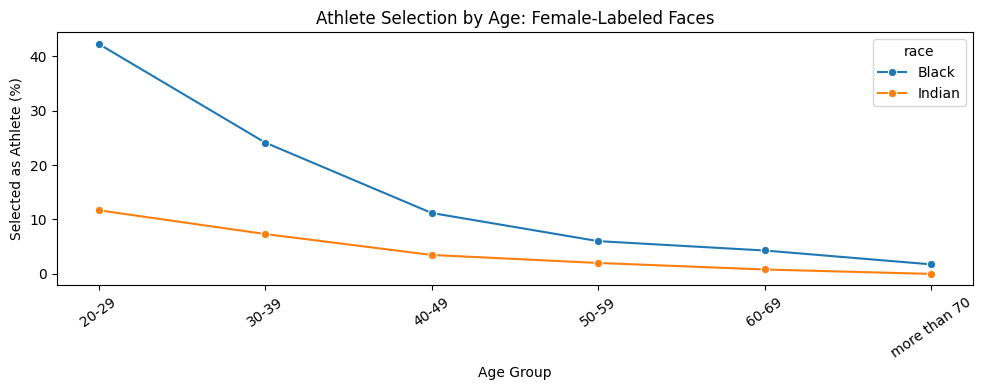

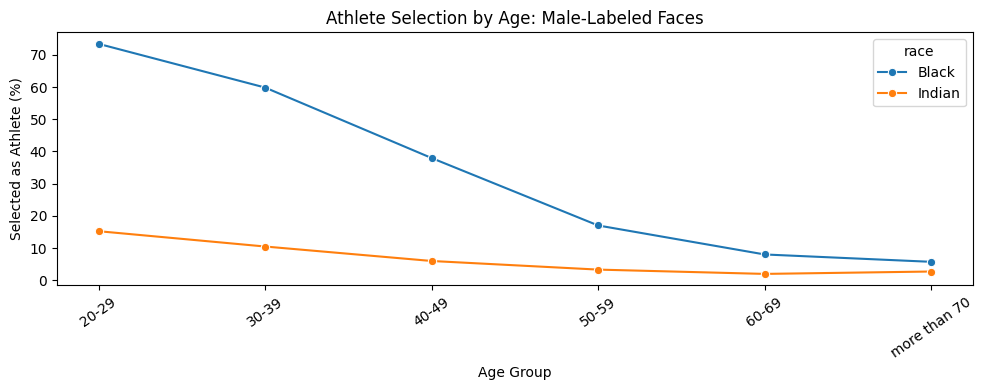

In [25]:

# Investigate athlete predictions by ethnicity, age and gender

focus = results[
    results["race"].isin(["Black", "Indian"])
].copy()

focus["athlete_selected"] = (
    focus["predicted_job"] == "athlete"
).astype(int)

athlete_age = focus.groupby(
    ["gender", "race", "age"]
)["athlete_selected"].agg(
    rate="mean",
    count="size"
).reset_index()

athlete_age["percentage"] = athlete_age["rate"] * 100

age_order = list(dataset.features["age"].names)

athlete_age["age"] = pd.Categorical(
    athlete_age["age"],
    categories=age_order,
    ordered=True
)

# Avoid drawing conclusions from very small groups
athlete_age = athlete_age[
    athlete_age["count"] >= 30
].sort_values("age")

display(athlete_age.round(1))

for gender in ["Female", "Male"]:

    subset = athlete_age[
        athlete_age["gender"] == gender
    ]

    plt.figure(figsize=(10, 4))

    sns.lineplot(
        data=subset,
        x="age",
        y="percentage",
        hue="race",
        marker="o"
    )

    plt.title(
        f"Athlete Selection by Age: {gender}-Labeled Faces"
    )
    plt.xlabel("Age Group")
    plt.ylabel("Selected as Athlete (%)")
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()


### Athlete selection by age, gender, and ethnicity

CLIP selected athlete more often for Black-labeled faces than for Indian-labeled faces in every age and gender comparison shown. At ages 20–29, the rates were 73.4% versus 15.2% among male-labeled faces and 42.3% versus 11.7% among female-labeled faces.

The difference narrowed in older groups. For male-labeled faces it fell from 58.2 percentage points at ages 20–29 to 32.0 points at ages 40–49 and 6.0 points at ages 60–69. The oldest Black male-labeled subgroup has 35 faces, so its rate can shift with a small number of selections.

## Study one occupation more deeply

In [26]:
##Study one occupation more deeply
##Let's investigate the occupation engineer.

##Maybe it shows a gender difference. Maybe it does not.

##First, calculate how often CLIP chooses engineer for every gender and ethnicity combination.


results["chose_engineer"] = (
    results["predicted_job"] == "engineer"
).astype(int)

engineer_groups = results.groupby(
    ["race", "gender"]
)["chose_engineer"].agg(
    rate="mean",
    count="size"
).reset_index()

engineer_groups["percentage"] = (
    engineer_groups["rate"] * 100
)

display(engineer_groups)


,race,gender,rate,count,percentage
0,Black,Female,0.008996,4891,0.899612
1,Black,Male,0.128933,4545,12.893289
2,East Asian,Female,0.025189,5280,2.518939
3,East Asian,Male,0.330914,4823,33.091437
4,Indian,Female,0.068082,4803,6.808245
5,Indian,Male,0.641130,5417,64.112978
6,Latino_Hispanic,Female,0.014108,5458,1.410773
7,Latino_Hispanic,Male,0.311879,5733,31.187860
8,Middle Eastern,Female,0.026046,2534,2.604578
9,Middle Eastern,Male,0.353038,6090,35.303777


### Reading the engineer subgroup table

The percentage in each row uses the faces with that combination of gender and ethnicity labels as its denominator. The counts range from 2,534 Middle Eastern female-labeled faces to 8,291 White male-labeled faces.

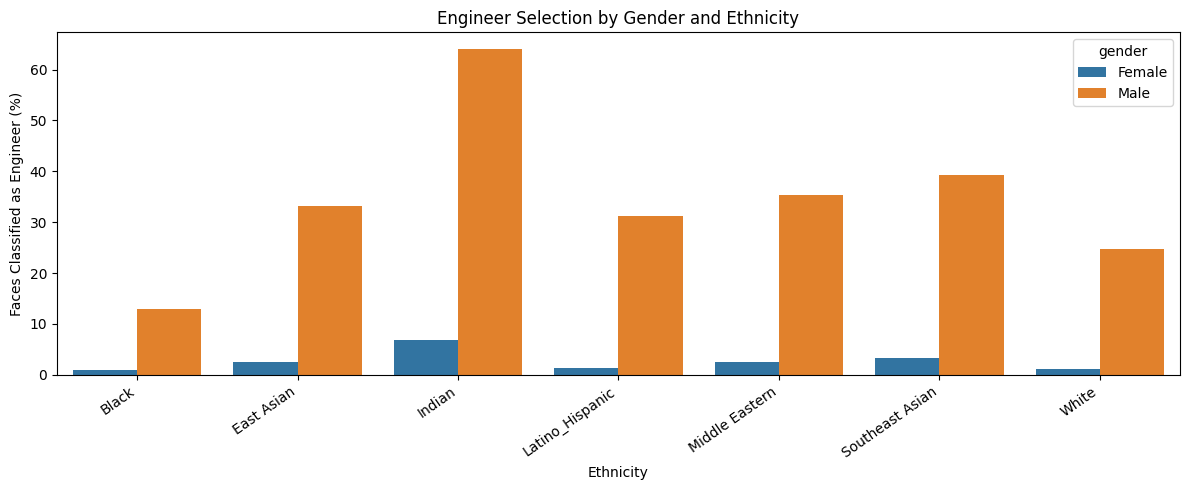

In [27]:

plt.figure(figsize=(12, 5))

sns.barplot(
    data=engineer_groups,
    x="race",
    y="percentage",
    hue="gender"
)

plt.title("Engineer Selection by Gender and Ethnicity")
plt.xlabel("Ethnicity")
plt.ylabel("Faces Classified as Engineer (%)")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.savefig("engineer_subgroups.png", dpi=200)
plt.show()


### The engineer gap varies across ethnicity labels

Engineer selection was higher for male-labeled faces in all seven ethnicity groups. The largest gap was among Indian-labeled faces (64.1% for male labels versus 6.8% for female labels, a 57.3-point difference). The smallest gap was among Black-labeled faces (12.9% versus 0.9%, a 12.0-point difference). A single pooled gender gap averages over this variation.

# Does age change the engineer association?
The next graph separates the model's engineer choices by age group and gender. We want to see whether the difference happens at every age, or mostly in some age groups.

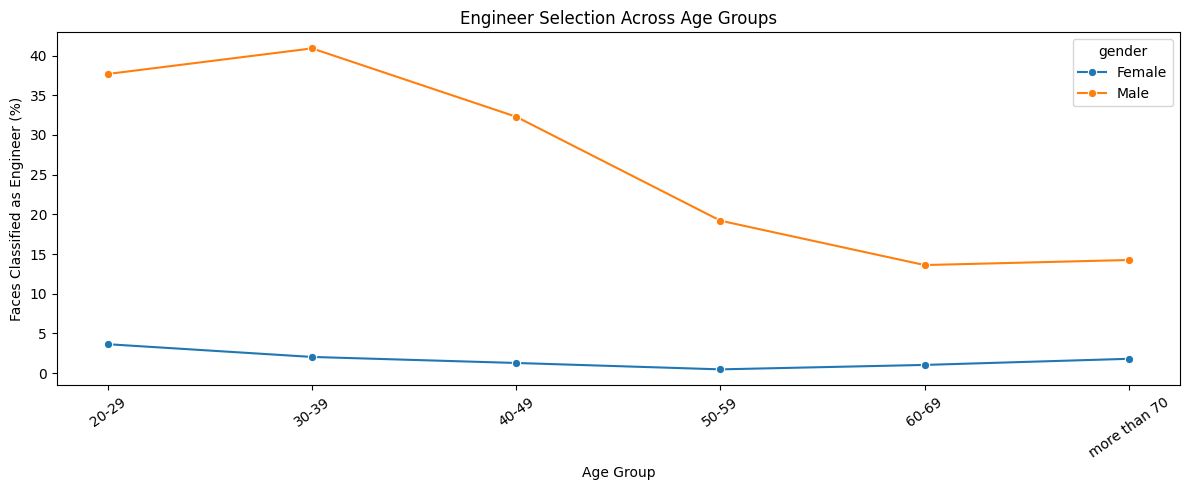

In [28]:

age_order = list(dataset.features["age"].names)

age_results = results.groupby(
    ["age", "gender"]
)["chose_engineer"].agg(
    percentage="mean",
    count="size"
).reset_index()

age_results["percentage"] *= 100

age_results["age"] = pd.Categorical(
    age_results["age"],
    categories=age_order,
    ordered=True
)

age_results = age_results.sort_values(
    ["gender", "age"]
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=age_results,
    x="age",
    y="percentage",
    hue="gender",
    marker="o",
    sort=False
)

plt.title("Engineer Selection Across Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Faces Classified as Engineer (%)")
plt.xticks(rotation=35)

plt.tight_layout()
plt.savefig("age_comparison.png", dpi=200)
plt.show()


### Engineer selection across age groups

The male-labeled engineer rate was about 38% at ages 20–29, peaked at about 41% at ages 30–39, and was about 14% in the two oldest age groups. The female-labeled rate stayed below 4% in each age group. The gap was widest at ages 30–39. The oldest age group contains 960 faces in total, compared with 21,580 at ages 30–39.

### Bootstrap interval for the engineer gap

We independently resample faces with replacement within each gender group and recalculate the male-minus-female engineer selection gap. The interval uses the 2.5th and 97.5th percentiles of 2,000 resampled gaps.

In [29]:

male = results.loc[
    results["gender"] == "Male",
    "chose_engineer"
].to_numpy()

female = results.loc[
    results["gender"] == "Female",
    "chose_engineer"
].to_numpy()

observed_difference = (
    male.mean() - female.mean()
) * 100

rng = np.random.default_rng(42)

differences = []

for _ in range(2000):
    male_sample = rng.choice(
        male, size=len(male), replace=True
    )
    female_sample = rng.choice(
        female, size=len(female), replace=True
    )

    difference = (
        male_sample.mean() -
        female_sample.mean()
    ) * 100

    differences.append(difference)

lower, upper = np.percentile(
    differences, [2.5, 97.5]
)

print("Observed difference:", round(observed_difference, 2))
print("95% bootstrap interval:", round(lower, 2), "to", round(upper, 2))


Observed difference: 31.52
95% bootstrap interval: 31.02 to 32.04


### Sampling variability of the engineer gap

The observed gap was **31.52 percentage points**, with a **95% bootstrap interval from 31.02 to 32.04 points**. The interval lies above zero and is narrow relative to the observed gap. It quantifies variability under resampling of the recorded faces.

Compare people within similar age and ethnicity groups

In [30]:

subgroup = results.groupby(
    ["race", "age", "gender"]
)["chose_engineer"].agg(
    rate="mean",
    count="size"
).reset_index()

rates = subgroup.pivot(
    index=["race", "age"],
    columns="gender",
    values="rate"
)

counts = subgroup.pivot(
    index=["race", "age"],
    columns="gender",
    values="count"
)

valid = (
    (counts["Male"] >= 10) &
    (counts["Female"] >= 10)
)

if valid.any():
    differences = (
        rates.loc[valid, "Male"] -
        rates.loc[valid, "Female"]
    )

    weights = counts.loc[
        valid, ["Male", "Female"]
    ].sum(axis=1)

    adjusted_difference = np.average(
        differences,
        weights=weights
    ) * 100

    print(
        "Difference after comparing age/ethnicity groups:",
        round(adjusted_difference, 2),
        "percentage points"
    )
    print("Groups compared:", valid.sum())
else:
    print("Not enough pictures in the subgroups.")


Difference after comparing age/ethnicity groups: 32.03 percentage points
Groups compared: 42


### The engineer gap within age and ethnicity groups

The size-weighted gender gap was **32.03 percentage points** across 42 age × ethnicity groups with at least 10 faces per gender label. That is close to the pooled gap of 31.52 points. The engineer difference persists when comparing faces with the same recorded age and ethnicity categories. Other image features can still vary within those groups.

# Investigate the pictures themselves

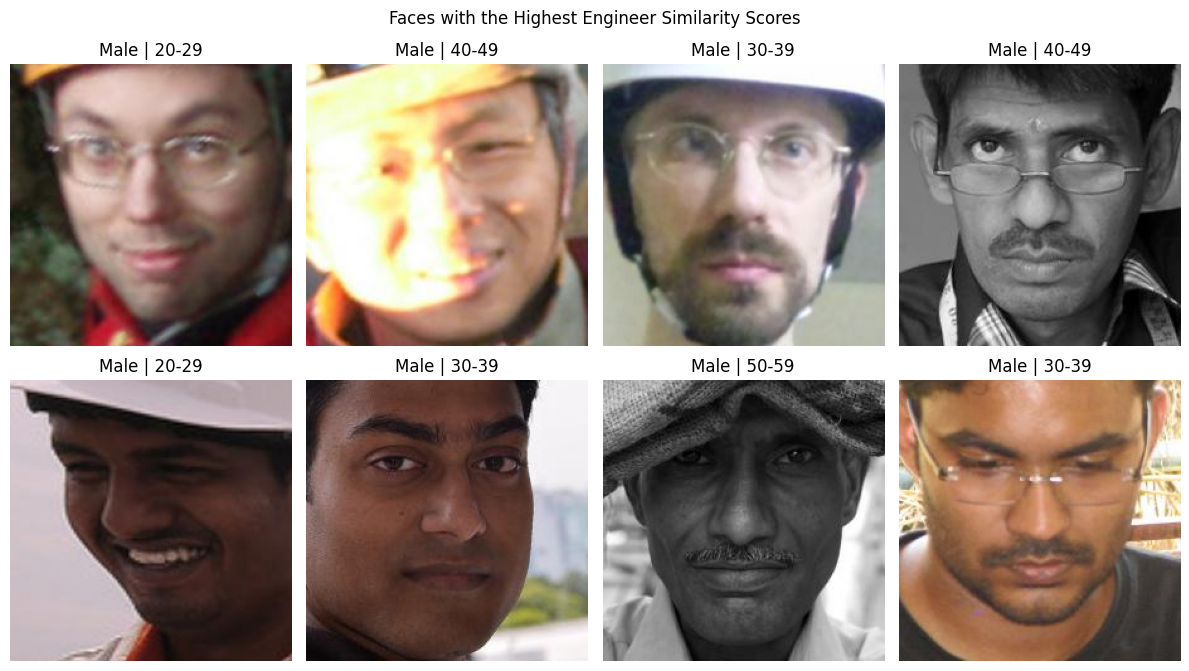

In [31]:
##Find pictures that CLIP strongly connects with "engineer"

examples = results.nlargest(
    8, "sim_engineer"
)

fig, axes = plt.subplots(2, 4, figsize=(12, 7))

for ax, (_, row) in zip(axes.flat, examples.iterrows()):

    face = dataset[
        int(row["image_index"])
    ]["image"]

    ax.imshow(face)
    ax.set_title(
        f"{row['gender']} | {row['age']}"
    )
    ax.axis("off")

plt.suptitle(
    "Faces with the Highest Engineer Similarity Scores"
)

plt.tight_layout()
plt.savefig("engineer_examples.png", dpi=200)
plt.show()


### Visible features in the highest engineer scores

All eight faces in the grid carry FairFace's Male label, and seven fall in the 20–49 age groups. Several images show eyewear or headwear, sometimes together. The grid illustrates features that occur among high-scoring examples. The glasses experiment uses a broader set of annotated faces to compare selection rates.

Research question — Does changing only the words change CLIP's answers?
CLIP compares each photo with a list of sentences. We try three ways of describing the same eight jobs:
1. “A portrait photo of a …”
2. “A photo of a person whose job is a …”
3. “A photo of someone working as a …”

The pictures and the model do not change. Only the sentences change. So a difference here shows prompt sensitivity.

In [32]:
prompt_rows = []

for version, predictions in predictions_by_prompt.items():
    agreement = (
        predictions == results["predicted_job"].to_numpy()
    ).mean() * 100

    print(
        version,
        "agreement with original:",
        round(agreement, 1),
        "%"
    )

    for gender in ["Male", "Female"]:
        mask = results["gender"].to_numpy() == gender

        engineer_rate = (
            predictions[mask] == "engineer"
        ).mean() * 100

        prompt_rows.append({
            "prompt": version,
            "gender": gender,
            "engineer_percent": engineer_rate
        })

prompt_results = pd.DataFrame(prompt_rows)

display(prompt_results)

portrait agreement with original: 100.0 %
person agreement with original: 57.6 %
working agreement with original: 54.0 %


,prompt,gender,engineer_percent
0,portrait,Male,34.061945
1,portrait,Female,2.544574
2,person,Male,22.698654
3,person,Female,3.043567
4,working,Male,6.331556
5,working,Female,0.469812


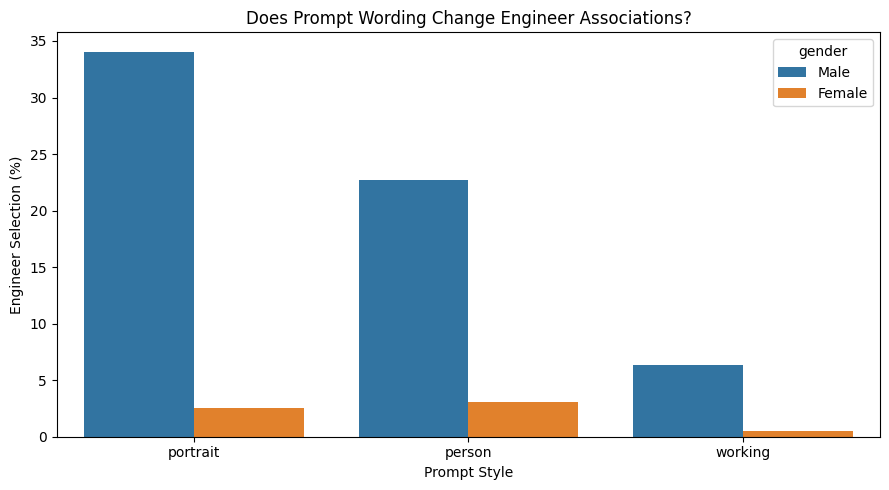

In [33]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=prompt_results,
    x="prompt",
    y="engineer_percent",
    hue="gender"
)

plt.title("Does Prompt Wording Change Engineer Associations?")
plt.ylabel("Engineer Selection (%)")
plt.xlabel("Prompt Style")

plt.tight_layout()
plt.savefig("prompt_sensitivity.png", dpi=200)
plt.show()


### Prompt wording changes occupation choices

Compared with the portrait template, the person template changed the top occupation for **42.4%** of faces, and the working template changed it for **46.0%**.

| Prompt template | Engineer, male-labeled | Engineer, female-labeled | Gap (percentage points) |
|---|---:|---:|---:|
| Portrait | 34.06% | 2.54% | 31.52 |
| Person | 22.70% | 3.04% | 19.66 |
| Working | 6.33% | 0.47% | 5.86 |

The working template reduced engineer selection in both gender groups and narrowed the gender gap. The faces and occupation list were held fixed for all three templates.

### Do closer rankings change more often?

,prompt,margin_group,changed_percent,count
0,person,Very small,63.1,18415
1,person,Small,53.2,18415
2,person,Large,39.7,18414
3,person,Very large,13.7,18415
4,working,Very small,63.5,18415
5,working,Small,54.8,18415
6,working,Large,43.6,18414
7,working,Very large,22.1,18415


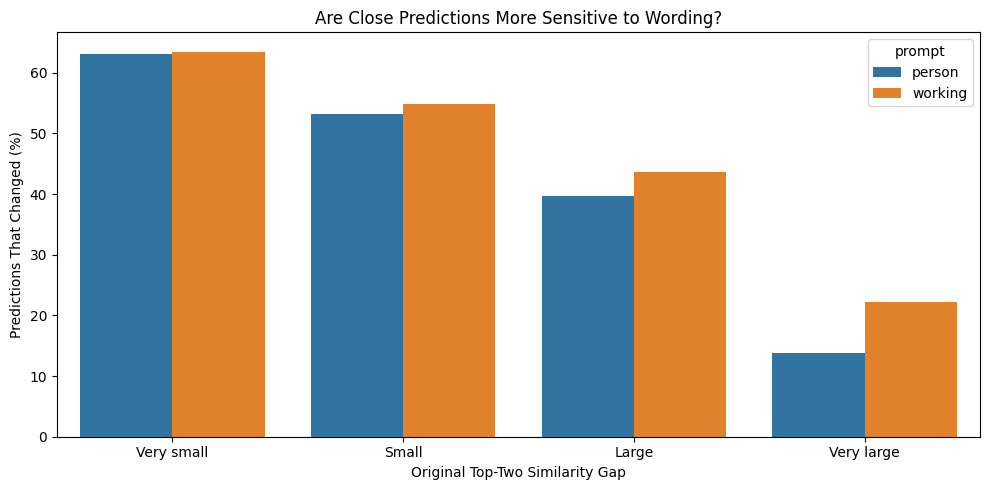

In [34]:
# Check whether uncertain predictions change more often

sorted_scores = np.sort(results[score_columns].to_numpy(), axis=1)

# Difference between highest and second-highest score
margin = sorted_scores[:, -1] - sorted_scores[:, -2]

margin_groups = pd.qcut(
    margin,
    4,
    labels=["Very small", "Small", "Large", "Very large"]
)

change_rows = []

for version in ["person", "working"]:

    new_predictions = predictions_by_prompt[version]

    changed = (
        new_predictions != results["predicted_job"].to_numpy()
    )

    temp = pd.DataFrame({
        "margin_group": margin_groups,
        "changed": changed
    })

    summary = temp.groupby(
        "margin_group", observed=True
    )["changed"].agg(["mean", "size"]).reset_index()

    for _, row in summary.iterrows():
        change_rows.append({
            "prompt": version,
            "margin_group": row["margin_group"],
            "changed_percent": row["mean"] * 100,
            "count": row["size"]
        })

change_table = pd.DataFrame(change_rows)
display(change_table.round(1))

plt.figure(figsize=(10, 5))

sns.barplot(
    data=change_table,
    x="margin_group",
    y="changed_percent",
    hue="prompt"
)

plt.title("Are Close Predictions More Sensitive to Wording?")
plt.xlabel("Original Top-Two Similarity Gap")
plt.ylabel("Predictions That Changed (%)")

plt.tight_layout()
plt.savefig("prompt_margin_analysis.png", dpi=200)
plt.show()

### Ranking gaps and wording sensitivity

The margin is the difference between the two highest portrait-prompt scores. The table divides faces into four nearly equal-sized groups by this margin. With the person template, 63.1% of the smallest-margin group changed occupation, compared with 13.7% of the largest-margin group. The corresponding rates for the working template were 63.5% and 22.1%.

For both templates, the switch rate fell at each step from the smallest to the largest margin group.

# Deeper test: compare all jobs, not only engineer.

In [35]:
# Compare occupation choices across the three prompt versions.
all_prompt_rows = []
for version, chosen in predictions_by_prompt.items():
    for gender in ["Female", "Male"]:
        mask = results["gender"].to_numpy() == gender
        for job in occupations:
            all_prompt_rows.append({"prompt": version, "gender": gender,
                                    "occupation": job,
                                    "selected_percent": 100*(chosen[mask] == job).mean()})

prompt_all_jobs = pd.DataFrame(all_prompt_rows)
for gender in ["Female", "Male"]:
    display(prompt_all_jobs[prompt_all_jobs.gender == gender].pivot(
        index="occupation", columns="prompt", values="selected_percent"
    ).round(1))

prompt,person,portrait,working
occupation,,,
artist,11.2,15.0,5.9
athlete,5.0,15.2,7.5
doctor,7.6,0.2,2.2
engineer,3.0,2.5,0.5
nurse,25.1,19.4,13.9
professor,14.1,6.5,6.1
scientist,2.8,1.0,0.5
teacher,31.1,40.1,63.4


prompt,person,portrait,working
occupation,,,
artist,11.8,8.8,5.7
athlete,22.0,25.2,20.3
doctor,9.7,5.5,8.9
engineer,22.7,34.1,6.3
nurse,2.5,0.7,0.9
professor,9.4,18.6,19.3
scientist,6.6,0.7,1.0
teacher,15.2,6.5,37.6


### Teacher selection across the three templates

Teacher was selected for 40.1%, 31.1%, and 63.4% of female-labeled faces under the portrait, person, and working templates, respectively. The rates for male-labeled faces were 6.5%, 15.2%, and 37.6%.

Teacher was the most frequent choice for female-labeled faces with all three templates. Among male-labeled faces, the most frequent choice shifted from engineer with the portrait and person templates to teacher with the working template.

## PCA of CLIP's occupation scores

Each face has eight similarity scores, one for each original portrait prompt. We fit PCA to all eight scores for all faces. Each point represents one face, and its position summarizes its score profile along the two directions with the most variation. The component weights show how each occupation score contributes to each axis.

To run this section in a fresh kernel, run the imports and occupation setup cells first. The PCA can read the adult run's `clip_output_scores.csv` or an earlier `clip_results.csv` from the working directory.

In [36]:
pca_source = results if "results" in globals() else read_saved_scores()
pca_results = pca_source[
    ["gender", "race", "age", "predicted_job", *score_columns]
].copy()
pca_scores = pca_results[score_columns]

pca = PCA(n_components=2, svd_solver="full")
pca_results[["PC1", "PC2"]] = pca.fit_transform(pca_scores)
pca_variance = 100 * pca.explained_variance_ratio_

print(f"Faces included: {len(pca_results):,}")
print(
    f"Score variance explained: PC1 {pca_variance[0]:.1f}%, "
    f"PC2 {pca_variance[1]:.1f}%, combined {pca_variance.sum():.1f}%"
)
component_weights = pd.DataFrame(
    pca.components_.T,
    index=pd.Index(occupations, name="Occupation"),
    columns=["PC1 weight", "PC2 weight"],
)
display(component_weights.round(3))

Faces included: 73,659
Score variance explained: PC1 72.8%, PC2 12.6%, combined 85.4%


,PC1 weight,PC2 weight
Occupation,,
doctor,0.356,-0.126
nurse,0.324,0.836
engineer,0.374,-0.412
scientist,0.423,-0.153
professor,0.402,-0.138
teacher,0.392,0.234
artist,0.281,-0.060
athlete,0.233,-0.116


### What the PCA axes measure

PC1 explains **72.8%** of score variance and PC2 explains **12.6%**, for **85.4%** combined. All eight PC1 weights are positive, so moving right generally corresponds to higher scores across occupations. On PC2, nurse has a large positive weight (+0.836), teacher has a smaller positive weight (+0.234), and engineer has the largest negative weight (−0.412).

The two panels display the same 5,000 faces, colored by FairFace gender label and by the model's top-ranked occupation. The dashed lines mark quartiles of PC1 for the full sample.

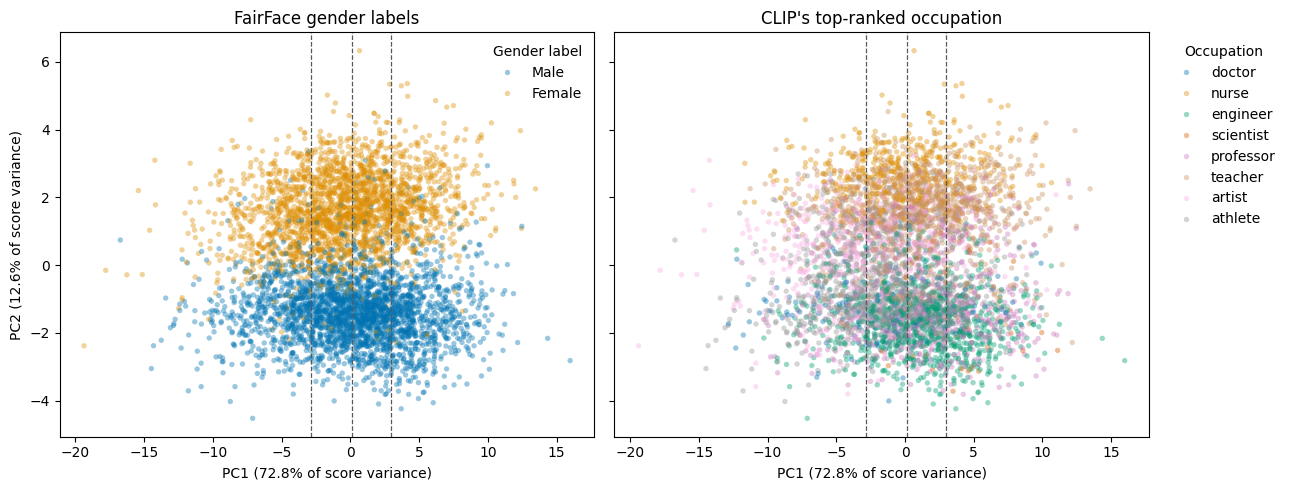

In [37]:
pc1_bands, pc1_edges = pd.qcut(
    pca_results["PC1"], q=4, retbins=True, duplicates="drop"
)
pca_results["pc1_band"] = pc1_bands.cat.rename_categories(
    [f"Band {i + 1}" for i in range(len(pc1_bands.cat.categories))]
)
pca_sample = pca_results.sample(n=min(5000, len(pca_results)), random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
sns.scatterplot(
    data=pca_sample, x="PC1", y="PC2", hue="gender", palette="colorblind",
    alpha=0.4, s=15, linewidth=0, ax=axes[0],
)
sns.scatterplot(
    data=pca_sample, x="PC1", y="PC2", hue="predicted_job",
    hue_order=occupations, palette="colorblind",
    alpha=0.4, s=15, linewidth=0, ax=axes[1],
)
axes[0].set_title("FairFace gender labels")
axes[1].set_title("CLIP's top-ranked occupation")
axes[0].set_ylabel(f"PC2 ({pca_variance[1]:.1f}% of score variance)")
axes[1].set_ylabel("")
axes[0].legend(title="Gender label", frameon=False)
axes[1].legend(
    title="Occupation", loc="upper left", bbox_to_anchor=(1.02, 1),
    frameon=False,
)
for ax in axes:
    ax.set_xlabel(f"PC1 ({pca_variance[0]:.1f}% of score variance)")
    for cut in pc1_edges[1:-1]:
        ax.axvline(cut, color="0.35", linestyle="--", linewidth=0.9)
fig.tight_layout()
plt.show()

### Patterns in the score map

The plotted female-labeled faces are concentrated at positive PC2 values and the male-labeled faces at negative PC2 values, with overlap near zero. In the occupation panel, nurse and teacher appear more often toward positive PC2 and engineer toward negative PC2. The gender labels were added as colors after fitting PCA to the eight occupation scores.

The tables below compare the four PC1 bands with the full sample. Each band contains about 18,415 faces by construction. The heatmap gives mean score differences relative to the full sample.

Face count and median top-two score gap


,Faces,Median_gap
pc1_band,,
Band 1,18415,0.5533
Band 2,18415,0.4596
Band 3,18414,0.4455
Band 4,18415,0.4490


Gender label (% of faces in each row)


gender,Female,Male
pc1_band,,
Band 1,50.0,50.0
Band 2,48.2,51.8
Band 3,46.5,53.5
Band 4,41.4,58.6
All faces,46.5,53.5


Ethnicity label (% of faces in each row)


race,Black,East Asian,Indian,Latino_Hispanic,Middle Eastern,Southeast Asian,White
pc1_band,,,,,,,
Band 1,19.3,9.6,10.5,18.5,11.2,9.3,21.6
Band 2,14.4,11.4,12.9,16.3,12.4,11.5,21.0
Band 3,10.6,14.0,15.4,14.1,12.4,12.5,21.0
Band 4,6.8,20.0,16.6,11.9,10.8,13.7,20.2
All faces,12.8,13.7,13.9,15.2,11.7,11.8,20.9


Age group (% of faces in each row)


age,20-29,30-39,40-49,50-59,60-69,more than 70
pc1_band,,,,,,
Band 1,47.3,26.8,13.6,8.2,3.2,0.8
Band 2,40.5,29.1,15.7,9.3,4.3,1.2
Band 3,37.7,30.1,16.8,9.7,4.1,1.5
Band 4,31.5,31.1,19.6,10.9,5.2,1.7
All faces,39.2,29.3,16.4,9.5,4.2,1.3


Top-ranked occupation (% of faces in each row)


predicted_job,doctor,nurse,engineer,scientist,professor,teacher,artist,athlete
pc1_band,,,,,,,,
Band 1,4.6,9.0,10.8,0.2,6.2,12.5,22.1,34.6
Band 2,3.3,11.0,18.6,0.3,10.3,21.1,12.0,23.4
Band 3,2.3,10.0,23.2,0.8,14.0,25.7,8.3,15.6
Band 4,2.1,7.4,25.1,2.0,21.3,29.0,4.4,8.6
All faces,3.1,9.4,19.4,0.8,13.0,22.1,11.7,20.6


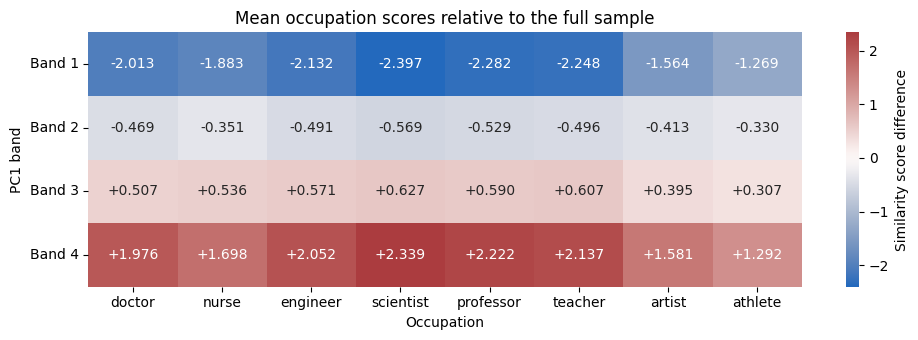

In [38]:
sorted_pca_scores = np.sort(pca_scores.to_numpy(), axis=1)
pca_results["top_two_gap"] = sorted_pca_scores[:, -1] - sorted_pca_scores[:, -2]
band_groups = pca_results.groupby("pc1_band", observed=True)

print("Face count and median top-two score gap")
display(band_groups["top_two_gap"].agg(Faces="size", Median_gap="median").round(4))

for column, label in [
    ("gender", "Gender label"),
    ("race", "Ethnicity label"),
    ("age", "Age group"),
    ("predicted_job", "Top-ranked occupation"),
]:
    shares = pd.crosstab(
        pca_results["pc1_band"], pca_results[column],
        normalize="index", margins=True, margins_name="All faces",
    ) * 100
    if column == "predicted_job":
        shares = shares.reindex(columns=occupations, fill_value=0)
    print(f"{label} (% of faces in each row)")
    display(shares.round(1))

score_differences = band_groups[score_columns].mean().sub(pca_scores.mean())
score_differences.columns = occupations

fig, ax = plt.subplots(figsize=(10, 3.5))
sns.heatmap(
    score_differences, annot=True, fmt="+.3f", cmap="vlag", center=0,
    cbar_kws={"label": "Similarity score difference"}, ax=ax,
)
ax.set(title="Mean occupation scores relative to the full sample",
       xlabel="Occupation", ylabel="PC1 band")
ax.tick_params(axis="y", labelrotation=0)
fig.tight_layout()
plt.show()

In [39]:
engineer_by_band = (
    pca_results.assign(engineer_selected=pca_results["predicted_job"].eq("engineer"))
    .groupby(["pc1_band", "gender"], observed=True)["engineer_selected"]
    .agg(Faces="size", Engineer_selected="sum", Engineer_pct="mean")
)
engineer_by_band["Engineer_pct"] *= 100
print("Engineer selection by PC1 band and FairFace gender label")
display(engineer_by_band.round({"Engineer_pct": 1}))

Engineer selection by PC1 band and FairFace gender label


Faces  Engineer_selected  Engineer_pct
pc1_band gender                                        
Band 1   Female   9211                182           2.0
         Male     9204               1798          19.5
Band 2   Female   8883                231           2.6
         Male     9532               3187          33.4
Band 3   Female   8559                252           2.9
         Male     9855               4023          40.8
Band 4   Female   7616                207           2.7
         Male    10799               4409          40.8

### What differs across the PC1 bands

From the lowest to the highest PC1 band, athlete selection falls from 34.6% to 8.6%, while teacher rises from 12.5% to 29.0% and professor rises from 6.2% to 21.3%. The mean athlete score still rises across those bands, from 1.269 points below the full-sample mean to 1.292 points above it. Professor and teacher scores rise more, illustrating how a prompt can score higher on average while winning less often.

The highest PC1 band has fewer faces aged 20–29 (31.5% versus 47.3% in the lowest band), fewer Black-labeled faces (6.8% versus 19.3%), and more male-labeled faces (58.6% versus 50.0%). Engineer selection among male-labeled faces rises from 19.5% in the lowest band to 40.8% in the highest. The female-labeled rate stays between 2.0% and 2.9% across all four bands. The pooled change in engineer selection therefore accompanies both a shift in gender composition and a change within the male-labeled group.

The lowest PC1 band has the largest median top-two gap (0.5533 versus 0.4455–0.4596 in the other bands). Overall similarity level and separation between the two highest scores capture different properties of the rankings. The bands are descriptive slices of the same scores used to choose the occupations.

### What changes when nurse or athlete is removed?

We keep the images and their portrait-prompt scores fixed. For each smaller candidate list, CLIP's selection is the remaining occupation with the highest score.

,menu,gender,teacher_percent
0,All 8 jobs,Female,40.065365
1,All 8 jobs,Male,6.466108
2,Without nurse,Female,52.861186
3,Without nurse,Male,6.752983
4,Without athlete,Female,44.036885
5,Without athlete,Male,8.882965
6,Without nurse or athlete,Female,60.089294
7,Without nurse or athlete,Male,9.284082


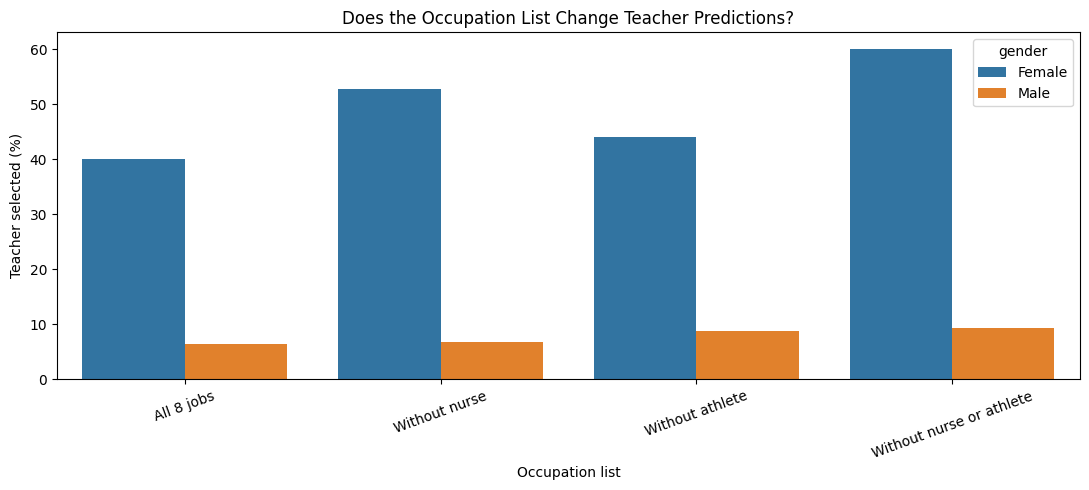

In [40]:
job_lists = {
    "All 8 jobs": occupations,
    "Without nurse": [
        j for j in occupations if j != "nurse"
    ],
    "Without athlete": [
        j for j in occupations if j != "athlete"
    ],
    "Without nurse or athlete": [
        j for j in occupations
        if j not in ["nurse", "athlete"]
    ]
}

menu_rows = []

for menu_name, jobs in job_lists.items():

    scores = results[[f"sim_{job}" for job in jobs]].to_numpy()

    predictions = np.array(jobs)[
        scores.argmax(axis=1)
    ]

    for gender in ["Female", "Male"]:
        mask = results["gender"].to_numpy() == gender

        teacher_percent = (
            predictions[mask] == "teacher"
        ).mean() * 100

        menu_rows.append({
            "menu": menu_name,
            "gender": gender,
            "teacher_percent": teacher_percent
        })

menu_table = pd.DataFrame(menu_rows)

display(menu_table)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=menu_table,
    x="menu",
    y="teacher_percent",
    hue="gender"
)

plt.title("Does the Occupation List Change Teacher Predictions?")
plt.ylabel("Teacher selected (%)")
plt.xlabel("Occupation list")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

### The occupation list changes the teacher gap

Removing nurse raised teacher selection from 40.07% to 52.86% for female-labeled faces and from 6.47% to 6.75% for male-labeled faces. Removing athlete alone gave rates of 44.04% and 8.88%, respectively.

With both occupations removed, teacher was selected for 60.09% of female-labeled faces and 9.28% of male-labeled faces. The female-minus-male teacher gap widened from **33.60 to 50.81 percentage points**. Nurse competed with teacher particularly often for female-labeled faces in the original menu.

## Final Conclusion

This project investigated social biases in CLIP using **73,659 FairFace images** (age groups 20–29 and older) and eight occupation descriptions.

Our main findings are:

**Gender comparison:** CLIP selected teacher more often for female-labeled faces (40.07% versus 6.47%) and engineer more often for male-labeled faces (34.06% versus 2.54%). Nurse was also selected more frequently for female-labeled faces, while athlete was more common for male-labeled faces.

**Ethnicity comparison:** Athlete was selected for 40.1% of Black-labeled faces, compared with 8.6% of Indian-labeled faces. Engineer showed the opposite pattern, with 37.2% for Indian-labeled faces versus 6.7% for Black-labeled faces. These differences also appeared within gender groups. Scientist was rarely selected as the top occupation across all ethnicity groups.

**Age and subgroup analysis:** Engineer was particularly common among male-labeled adults aged 20–39, reaching approximately 41% for ages 30–39. The gender difference remained around 32.03 percentage points after comparing faces within similar age and ethnicity groups. The engineer gap was present across all seven ethnicity groups, although its size varied.

**Reliability test:** The engineer gender gap was 31.52 percentage points, with a 95% bootstrap interval of 31.02–32.04 points, suggesting a stable difference in our dataset.

**Face examples and glasses experiment:** Several pictures which had a high similarity score for the engineer profession showed glasses or other visible accessories. In our manually labeled sample of 314 faces, professor was selected for 36.8% of faces with glasses, compared with 7.8% without glasses. After adjusting for age, gender, and ethnicity, professor, scientist, teacher, and engineer still showed positive associations with glasses in their similarity scores. Further analysis showed that these patterns differed between gender groups.

**Prompt wording:** Changing the occupation descriptions caused 42.4%–46.0% of predictions to change. The engineer gender gap also decreased from 31.52 percentage points with the original prompt to 5.86 points with the working-related prompt. The prediction-margin experiment showed that faces with smaller differences between their two highest scores were more likely to receive a different occupation when the wording changed.

**Occupation-list experiment:** Removing nurse and athlete increased teacher selection for female-labeled faces from 40.07% to 60.09%, while the rate for male-labeled faces increased from 6.47% to 9.28%. The gender gap therefore widened from 33.60 to 50.81 percentage points, showing that CLIP's predictions depend on the available occupation choices.

**PCA analysis of occupation scores:** The PCA visualization showed partial separation by gender labels, with nurse and teacher appearing more often in one region and engineer in another. The first two principal components explained 85.4% of the variation in the eight occupation scores. Examining smaller PCA regions revealed differences in demographic composition and occupation rankings. For example, athlete selection decreased from 34.6% to 8.6% across the four PC1 groups, while teacher selection increased from 12.5% to 29.0%. This showed that similarity scores and top-ranked occupations do not always follow the same pattern.